# <center>🚀 Лекция 9. Внедрение ИИ-сервисов: от ноутбука до продакшена</center>
## <center>AI服务的部署与上线</center>

### <center>Прикладные технологии искусственного интеллекта</center>
#### <center>Модуль 5 — Развёртывание проектов ИИ · 2 академических часа (90 минут)</center>

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>🎯 Цели лекции:</b><br>
1. называть четыре пути внедрения модели (библиотека, локальный сервис, облачный API, edge) и их компромиссы;<br>2. сохранять и загружать модель с полной цепочкой преобразований (joblib);<br>3. объяснять архитектуру веб-сервиса: клиент → HTTP → Flask → модель → JSON;<br>4. читать мини-код Flask-сервиса и писать свой маршрут /predict;<br>5. понимать жизненный цикл MLOps: мониторинг, дрейф данных, переобучение, откат;<br>6. соблюдать базовую безопасность: ключи, приватность, лимиты, логи.
</div>

<div style='background-color: #FFF3E0; padding: 12px; border-left: 5px solid #FB8C00; margin: 20px 0;'>
<b>⏱️ План работы (90 минут):</b><br>
• Четыре пути внедрения модели <i>(10 мин)</i><br>• Артефакты: файлы модели и воспроизводимость <i>(10 мин)</i><br>• Веб-сервис: HTTP, Flask, JSON <i>(25 мин)</i><br>• Жизненный цикл: дрейф, мониторинг, MLOps <i>(15 мин)</i><br>• Скорость и нагрузка; чек-лист и безопасность <i>(15 мин)</i><br>• Мини-тест и итоги <i>(5 мин)</i>
</div>

<div style='background-color: #E3F2FD; padding: 12px; border-left: 5px solid #1976D2; margin: 20px 0;'>
<b>📦 Что понадобится:</b> Flask, joblib, PyTorch; mnist_cnn.pth из Практики 6.
</div>

<div style='background-color: #FCE4EC; padding: 12px; border-left: 5px solid #C2185B; margin: 20px 0;'>
<b>💡 Как работать с ноутбуком.</b> Теория читается сверху вниз; все рисунки уже внедрены в файл — внешние контейнеры и сетка не нужны. Демонстрационные ячейки с кодом можно запускать по порядку.
</div>


In [ ]:
# Настройка ноутбука: графики внутри документа, кириллица и иероглифы
%matplotlib inline
import numpy as np
import matplotlib.font_manager as fm
import os
for fp in ['/usr/share/fonts/truetype/chinese/NotoSansSC-Regular.ttf']:
    if os.path.exists(fp):
        fm.fontManager.addfont(fp)
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('Настройка завершена. Запускайте ячейки по порядку — сверху вниз.')

Настройка завершена. Запускайте ячейки по порядку — сверху вниз.


## 1. Куда «попадает» модель после ноутбука

Модель с точностью 98% в ноутбуке **ещё не продукт**. Пользователь не будет ставить Jupyter. Путь модели в бой:


## 1. Путь модели и понятие API (0–25 мин)

### 🛤️ Жизненный цикл модели ИИ
Модель бесполезна, если она остаётся только в тетради Jupyter. Чтобы ей могли пользоваться другие программы или люди, её нужно **развернуть (部署)**.

1. **Обучить (训练):** Написать код, подобрать параметры, достичь хорошей точности.
2. **Сохранить (保存):** Записать «мозги» модели (веса и структуру) в файл на диске (например, `.pth` для PyTorch, `.pkl` для scikit-learn).
3. **Загрузить (加载):** Программа-сервис читает этот файл и восстанавливает модель в памяти.
4. **Обслуживать (服务):** Программа принимает запросы от пользователей, передаёт данные модели и возвращает ответ.

### 🪟 Что такое API?
**API (Application Programming Interface, 应用程序接口)** — это «окошко в ресторане».
- **Клиент (вы):** читаете меню и отдаёте заказ через окошко (HTTP-запрос).
- **Кухня (сервер с моделью):** готовит блюдо, не показывая вам рецепты и грязную посуду.
- **Официант (API):** приносит вам готовый результат в стандартной упаковке (обычно формат **JSON**).

**JSON (JavaScript Object Notation)** — универсальный текстовый формат для обмена данными. Выглядит как словарь Python.
```json
{
  "status": "success",
  "prediction": "кошка",
  "confidence": 0.95
}
```

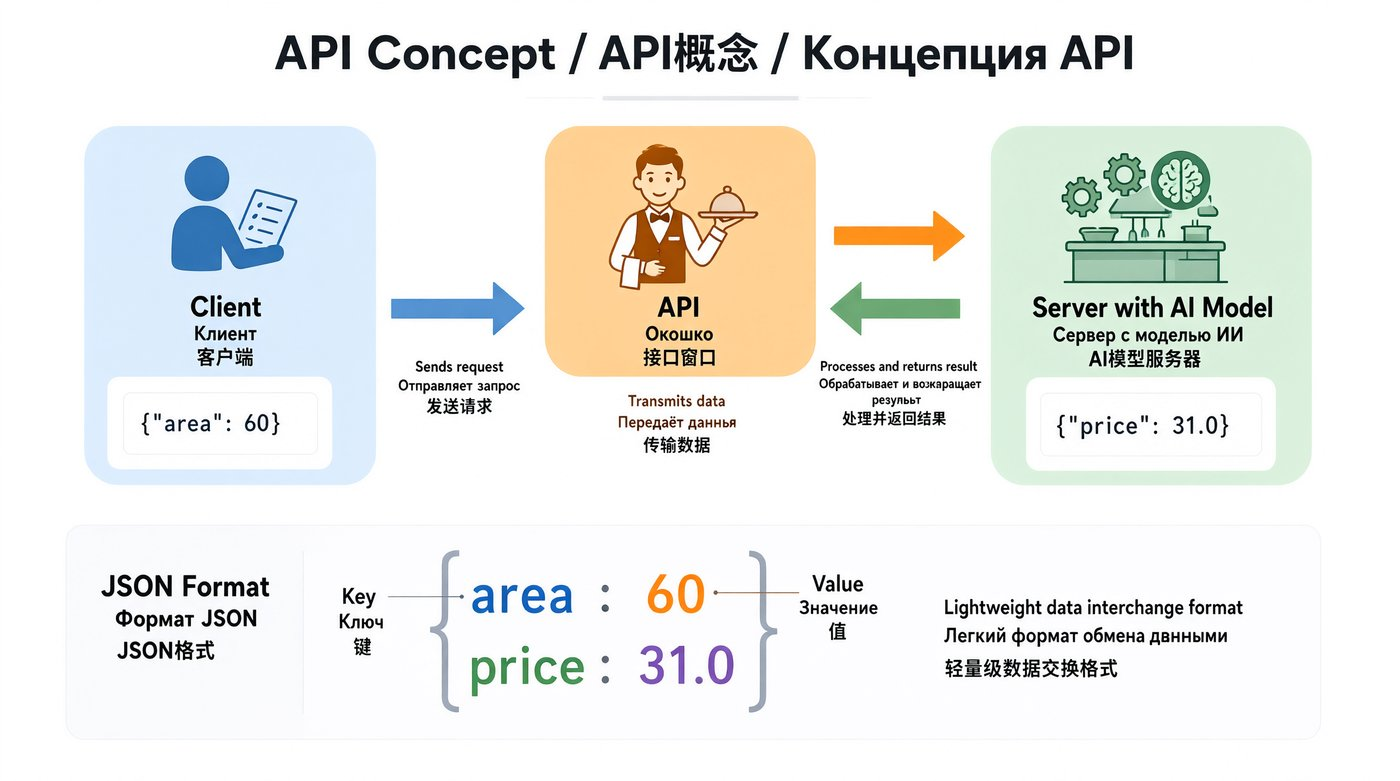

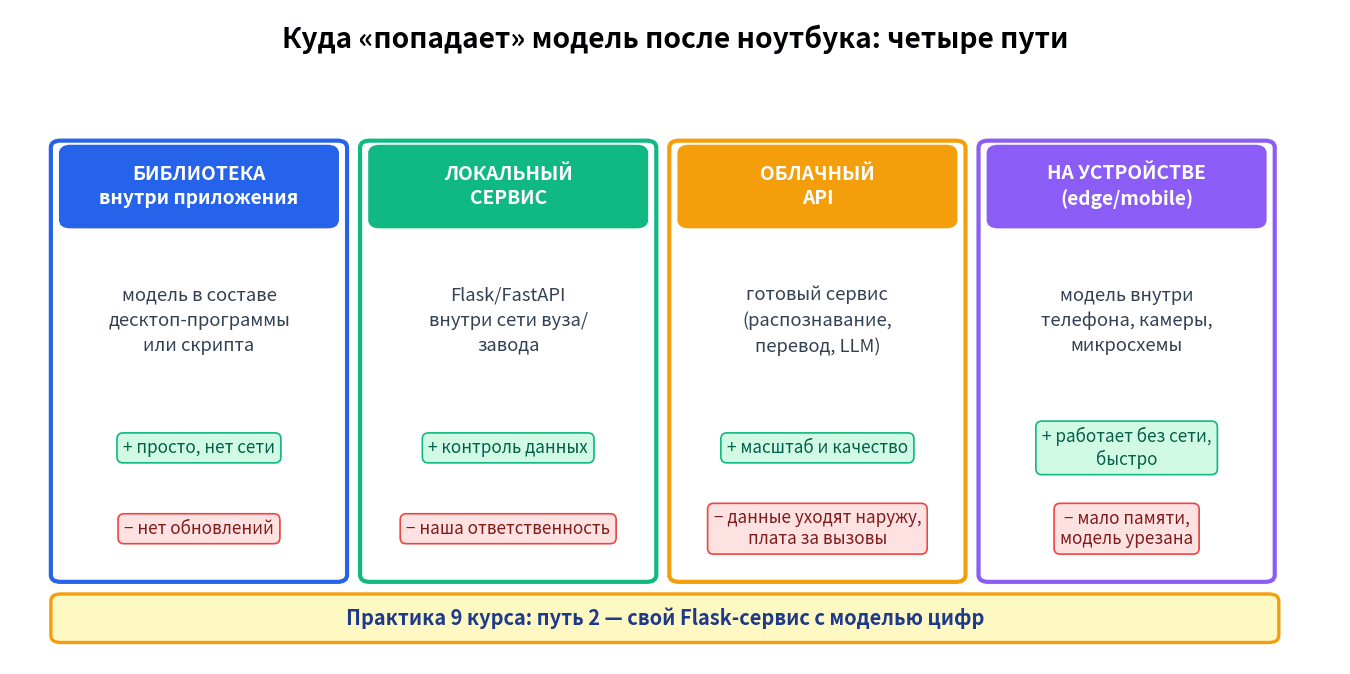

Решающая тройка вопросов: **где данные** (можно ли им уходить наружу?), **какая задержка** допустима, **кто обслуживает**. Для курсового проекта и лабораторий путь №2 (свой локальный сервис) — золотая середина: полный контроль, никаких платежей, всё работает в кампусной сети.


## 2. Артефакты: что сохранять, чтобы всё воспроизводилось


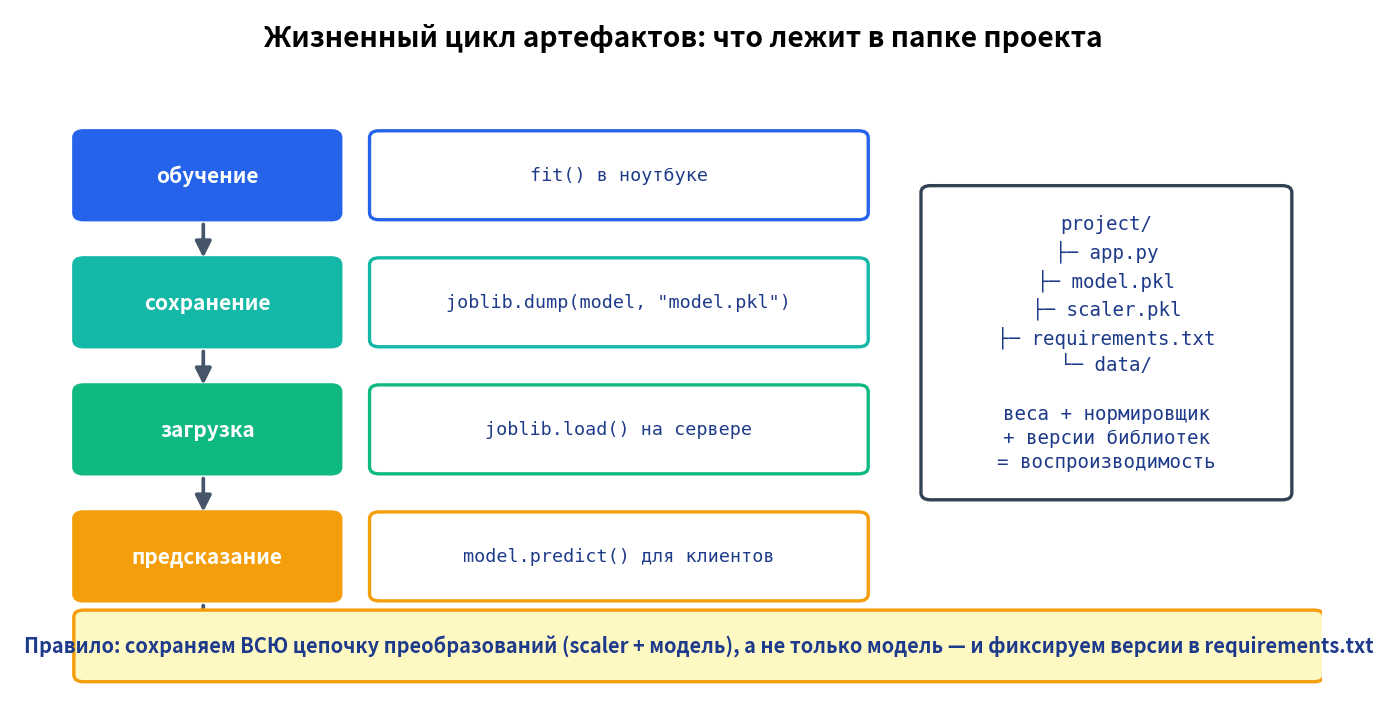

Три классические ошибки, из-за которых «вчера работало, сегодня нет»:

1. Сохранили модель, **но не scaler** — на сервере признаки нормируются иначе, точность рушится.
2. Обучили с `scikit-learn 1.3`, задеплоили с `0.24` — файл не читается или даёт другие ответы. Лечение: `requirements.txt` с точными версиями.
3. Нет тега в git — неизвестно, какие именно данные и код породили файл.

> **Мнемоника:** деплой = «веса + нормировщик + версии + данные для отката».


> 🎓 **Файл весов — «диплом» модели.** Архитектуру можно восстановить по коду, а накопленный опыт живёт именно в весах. Для scikit-learn модель целиком сериализуют в один файл (`joblib.dump` / `joblib.load`); для PyTorch в файл уходит словарь весов `torch.save(model.state_dict())` — при загрузке сначала создают модель той же архитектуры, затем наполняют её весами. На практике 9 мы сохраним модель распознавания цифр и загрузим её в веб-сервис.


In [ ]:
# Сохранение и загрузка модели (полная цепочка!)
from sklearn.datasets import load_iris
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import joblib

X, y = load_iris(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, random_state=0)

pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
pipe.fit(X_tr, y_tr)

joblib.dump(pipe, "data/iris_pipe.pkl")     # scaler + модель одним файлом

loaded = joblib.load("data/iris_pipe.pkl")  # на сервере
print("точность сохранённого конвейера:", f"{loaded.score(X_te, y_te):.2%}")
print("предсказание для нового цветка [5.1, 3.5, 1.4, 0.2]:",
      loaded.predict([[5.1, 3.5, 1.4, 0.2]])[0])

точность сохранённого конвейера: 97.37%
предсказание для нового цветка [5.1, 3.5, 1.4, 0.2]: 0


## 3. Веб-сервис: HTTP-дверь к модели

Протокол HTTP — общий язык всех клиентов и серверов. Наша схема:


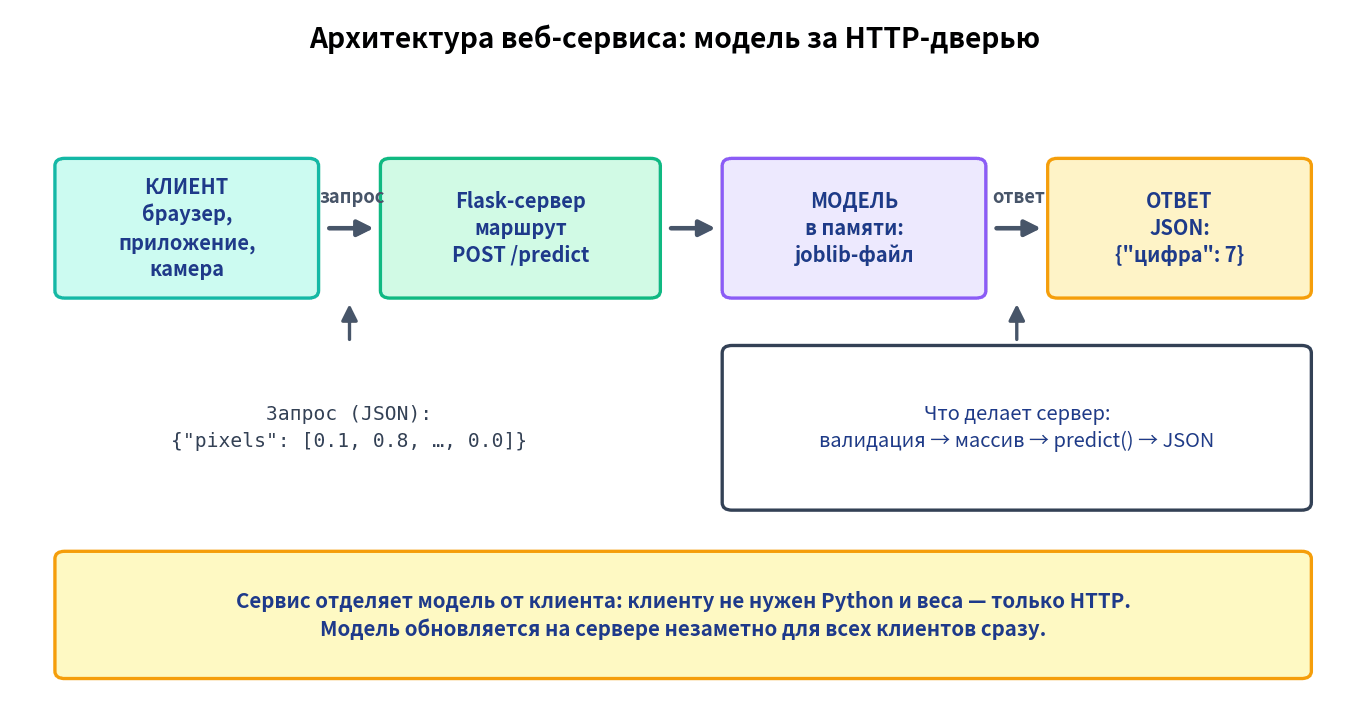

**Flask** — минимальный веб-фреймворк: весь сервер умещается в дюжину строк:


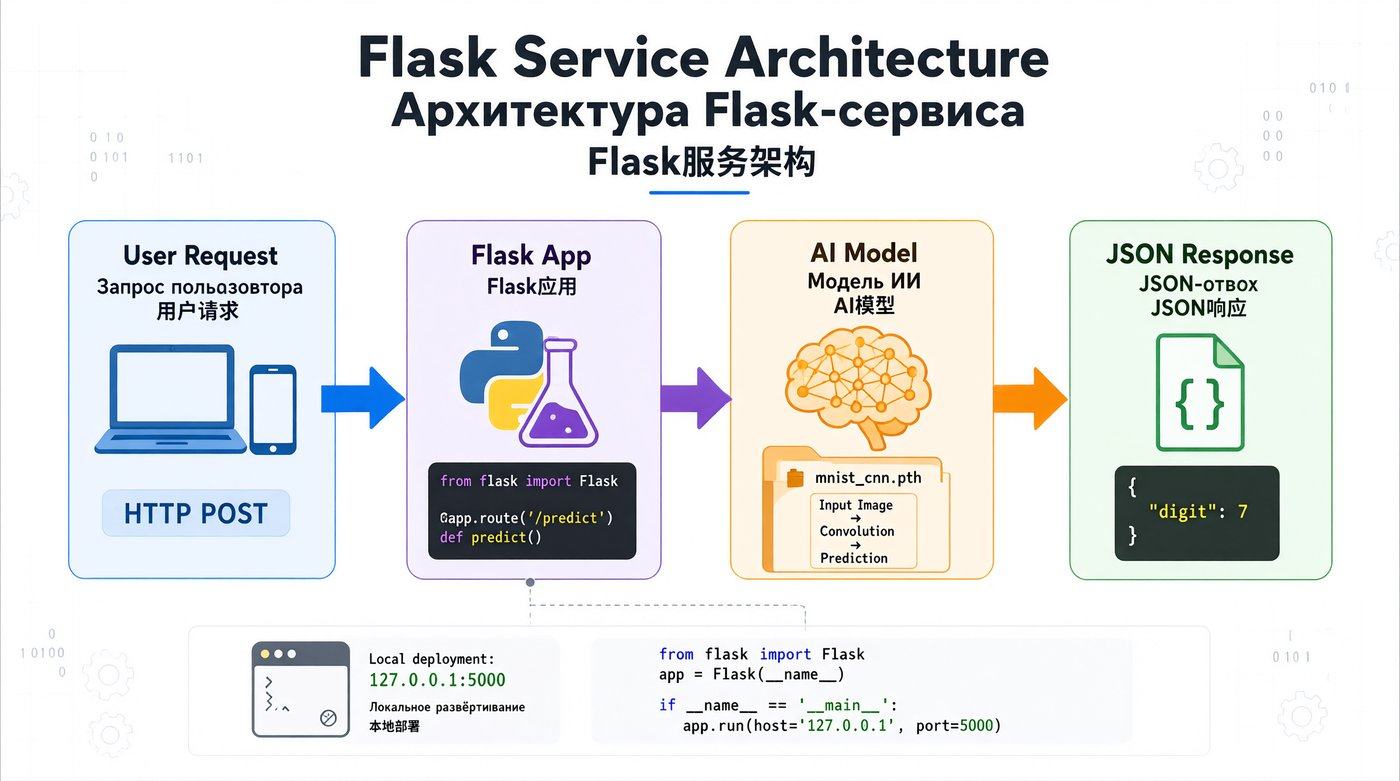

### 4.1 Flask: превращаем Python в веб-сервис (25–45 мин)

**Flask** — это микро-фреймворк на Python, который позволяет превратить обычную функцию в веб-адрес (URL) всего за несколько строк кода.

### 🌐 Где размещать сервис?
- **Локальное развёртывание (本地部署):** На своём компьютере (адрес `127.0.0.1` или `localhost`). Идеально для тестирования и учебных проектов.
- **Облачное развёртывание (云端部署):** На серверах Alibaba Cloud (阿里云), Tencent Cloud (腾讯云) или Huawei Cloud (华为云). Нужно, чтобы сервис был доступен всем в интернете.

### 💻 10 строк кода, которые меняют всё
Ниже приведён код, который вы будете использовать в **Практике 8**. Сохраните его в файл `app.py`.

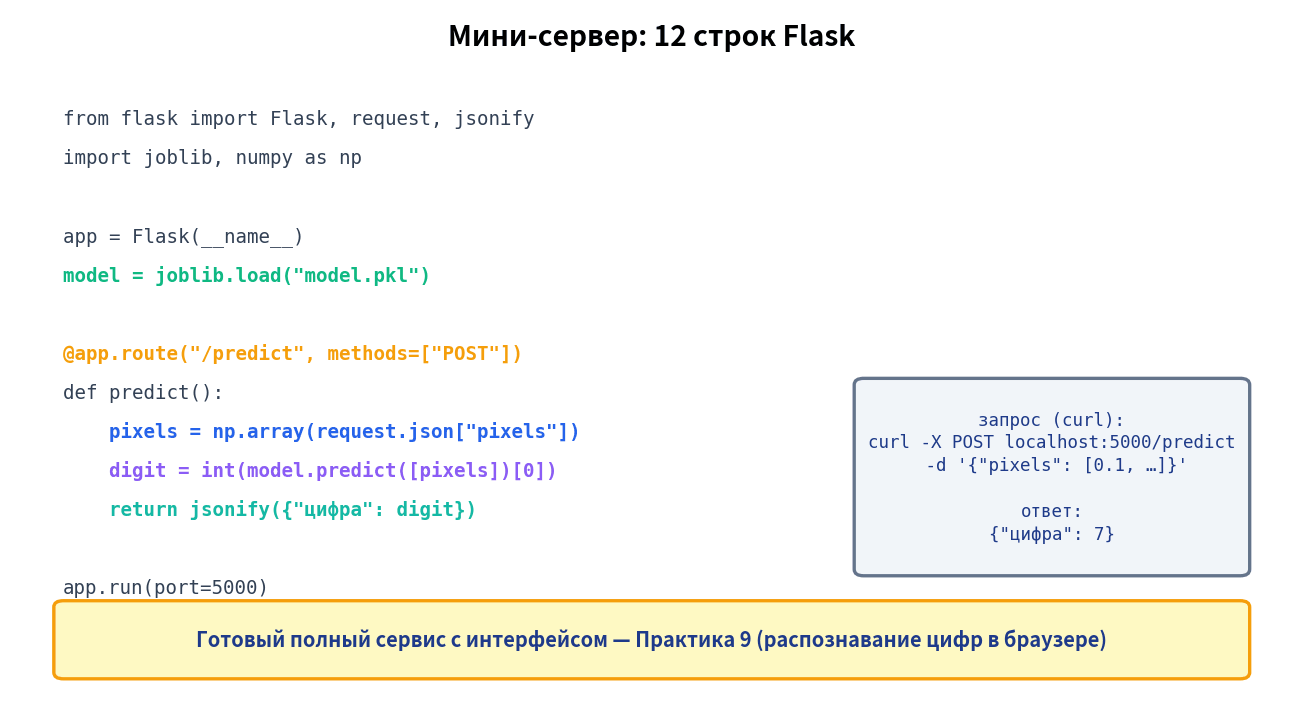

Разбор по ролям: `@app.route` публикует адрес `/predict` для метода POST; `request.json` разбирает тело запроса; `model.predict` — та же функция из лекции 3; `jsonify` упаковывает ответ. Никакой магии — просто обёртка над моделью.


In [ ]:
# Мини-сервис целиком (запускается ВНЕ ноутбука: python app.py)
# Здесь — для чтения; полный вариант с HTML-страницей рисовалки — Практика 9.

flask_app = """
from flask import Flask, request, jsonify
import joblib, numpy as np

app = Flask(__name__)
model = joblib.load("data/mnist_cnn_demo.joblib")   # веса загружаются ОДИН раз

@app.route("/predict", methods=["POST"])
def predict():
    pixels = np.array(request.json["pixels"])       # 784 числа от клиента
    digit = int(model.predict([pixels])[0])
    return jsonify({"цифра": digit})

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000)
"""
print(flask_app)

# а так выглядит вызов сервиса из любого кода:
call_example = """
import requests
r = requests.post("http://localhost:5000/predict",
                  json={"pixels": [0.1]*784})
print(r.json())   # {"цифра": ...}
"""
print(call_example)


from flask import Flask, request, jsonify
import joblib, numpy as np

app = Flask(__name__)
model = joblib.load("data/mnist_cnn_demo.joblib")   # веса загружаются ОДИН раз

@app.route("/predict", methods=["POST"])
def predict():
    pixels = np.array(request.json["pixels"])       # 784 числа от клиента
    digit = int(model.predict([pixels])[0])
    return jsonify({"цифра": digit})

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000)


import requests
r = requests.post("http://localhost:5000/predict",
                  json={"pixels": [0.1]*784})
print(r.json())   # {"цифра": ...}



In [ ]:
# Этот код нужно сохранить в отдельный файл app.py и запустить в терминале:
# python app.py

flask_code = """
from flask import Flask, request, jsonify

app = Flask(__name__)

# Это "окошко" нашего API. Метод POST означает, что мы отправляем данные.
@app.route('/predict', methods=['POST'])
def predict():
    # 1. Получаем данные из запроса (например, площадь квартиры)
    data = request.get_json()
    area = data.get('area', 0)

    # 2. Здесь должна быть загрузка модели: model = torch.load('model.pth')
    # 3. Делаем прогноз (упрощённая формула для примера)
    predicted_price = (area * 0.5) + 1.0

    # 4. Возвращаем результат в формате JSON
    return jsonify({
        "status": "success",
        "predicted_price": round(predicted_price, 2)
    })

if __name__ == '__main__':
    # Запускаем сервер на локальном компьютере, порт 5000
    app.run(host='127.0.0.1', port=5000, debug=True)
"""

print(flask_code)
print("\n💡 Чтобы проверить этот сервис, в другом окне или ячейке выполните:")
print("""
import requests
response = requests.post('http://127.0.0.1:5000/predict', json={'area': 60})
print(response.json())
""")


from flask import Flask, request, jsonify

app = Flask(__name__)

# Это "окошко" нашего API. Метод POST означает, что мы отправляем данные.
@app.route('/predict', methods=['POST'])
def predict():
    # 1. Получаем данные из запроса (например, площадь квартиры)
    data = request.get_json()
    area = data.get('area', 0)
    
    # 2. Здесь должна быть загрузка модели: model = torch.load('model.pth')
    # 3. Делаем прогноз (упрощённая формула для примера)
    predicted_price = (area * 0.5) + 1.0
    
    # 4. Возвращаем результат в формате JSON
    return jsonify({
        "status": "success",
        "predicted_price": round(predicted_price, 2)
    })

if __name__ == '__main__':
    # Запускаем сервер на локальном компьютере, порт 5000
    app.run(host='127.0.0.1', port=5000, debug=True)


💡 Чтобы проверить этот сервис, в другом окне или ячейке выполните:

import requests
response = requests.post('http://127.0.0.1:5000/predict', json={'area': 60})
print(response.json())



## 4. Модель в бою стареет: MLOps и дрейф

Деплой — не финиш. Данные в реальном мире меняются, и точность падает «сама по себе»:


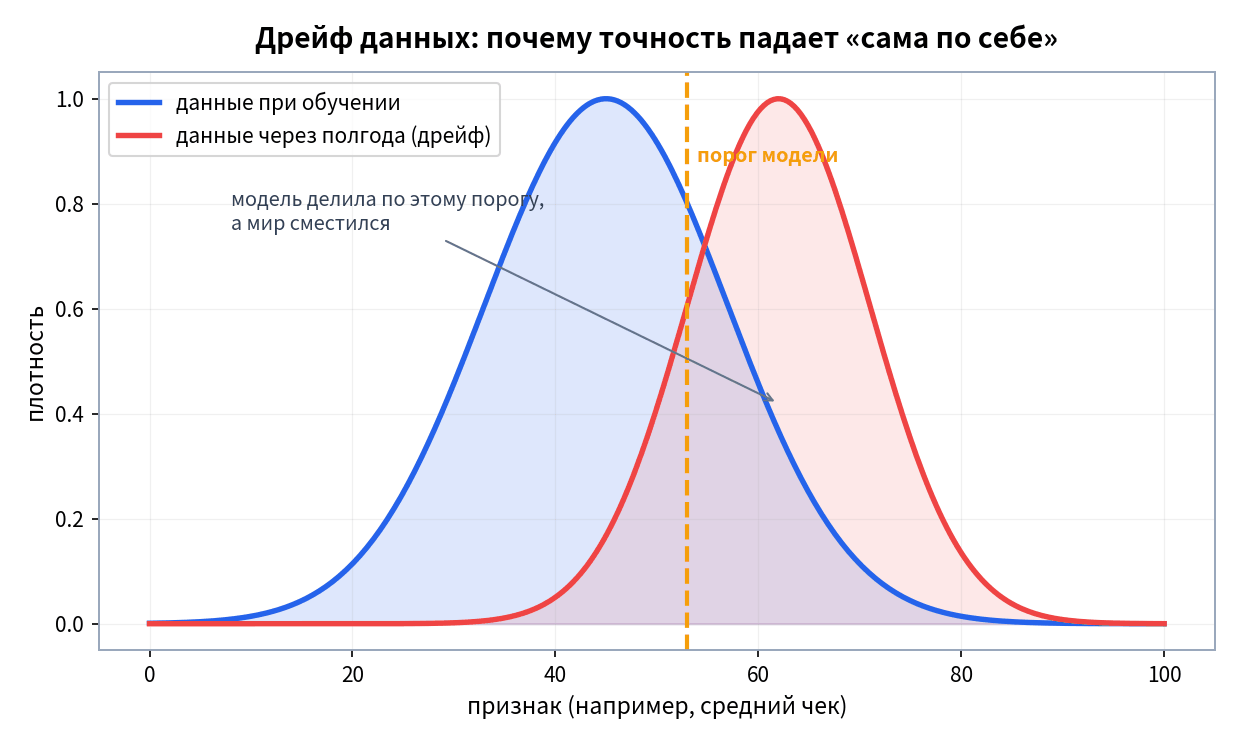

Классические истории: скоринговая модель, обученная до экономического сдвига; детектор брака, когда поставщик поменял покрытие деталей; рекомендации, когда аудитория выросла и помолодела. Диагноз ставит **мониторинг**: распределение входов и качество на живом потоке.


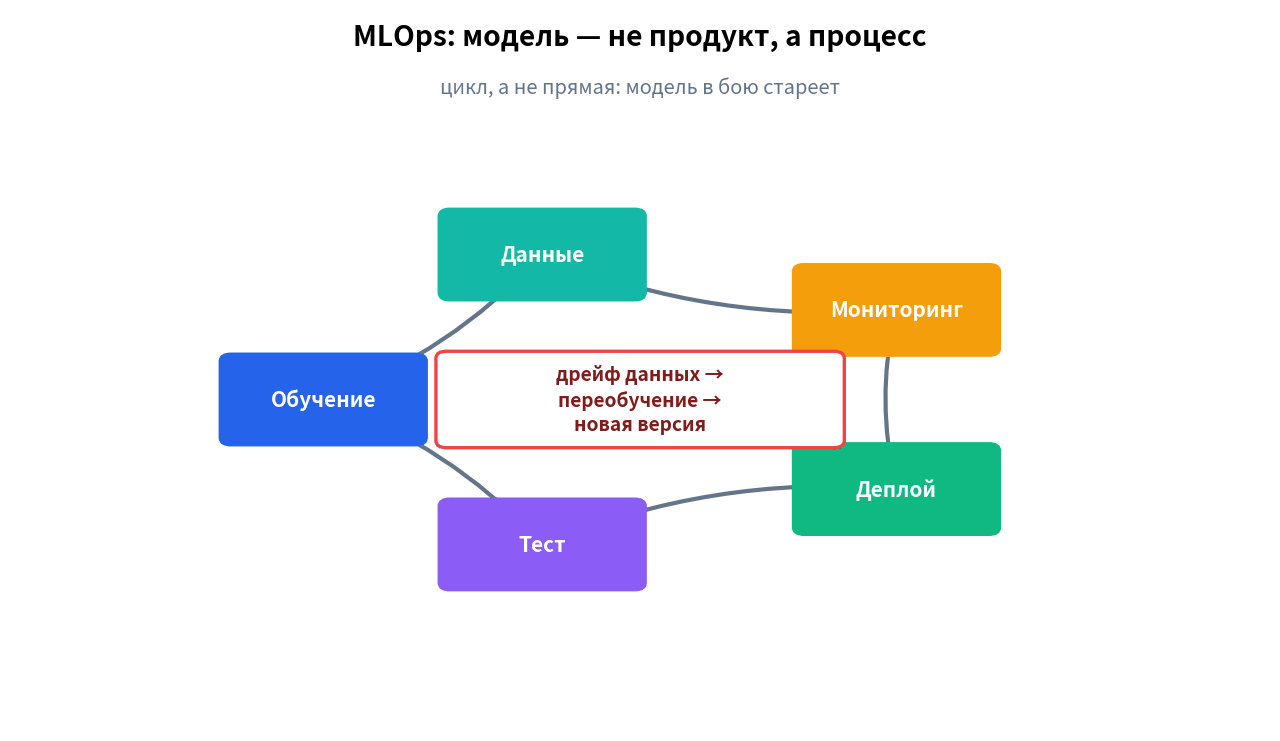

Поэтому индустрия говорит не «обучили модель», а **MLOps** — цикл: данные → обучение → тест → деплой → мониторинг → (дрейф?) → переобучение. Инструменты цикла (MLflow, Airflow) — за рамками курса, но понимание цикла обязательно.



### 🩺 «Пульс» сервиса: пять показателей здоровья

Зрелые команды следят за пятью величинами — их достаточно, чтобы заметить большинство проблем раньше пользователей:

1. **доля запросов с ошибками**;
2. **среднее время ответа**;
3. **средняя уверенность модели**;
4. **распределение предсказанных классов** — если 90 % ответов внезапно стали «единица», где-то сломалось выравнивание изображения;
5. **частота запросов**.

> 🌱 **Метафора для запоминания:** модель, пересаженная из теплицы (ноутбука) в открытый грунт (продакшен), требует регулярного полива и осмотра — мониторинг и периодическое дообучение на свежих данных.


## 5. Скорость, чек-лист, безопасность

### 5.1. Три класса задач по скорости


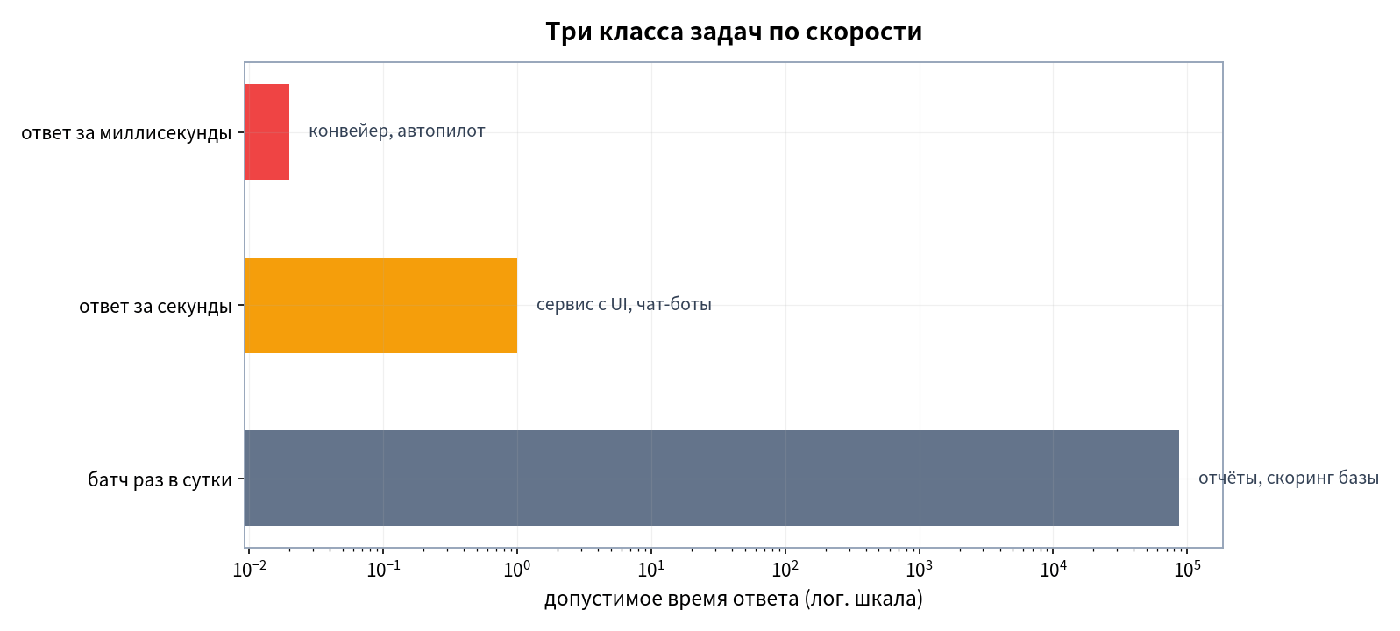

Батчу хватает часов; интерфейсу — секунды; конвейеру — миллисекунды. Отсюда приёмы ускорения, которые пригодятся в разговоре с работодателем: **батчинг** запросов, **квантизация** (веса float32 → int8, модель в 4 раза легче), экспорт в **ONNX**, вынос тяжёлых моделей на GPU. Для наших учебных сервисов всё это опционально.

### 5.2. Чек-лист перед продакшеном


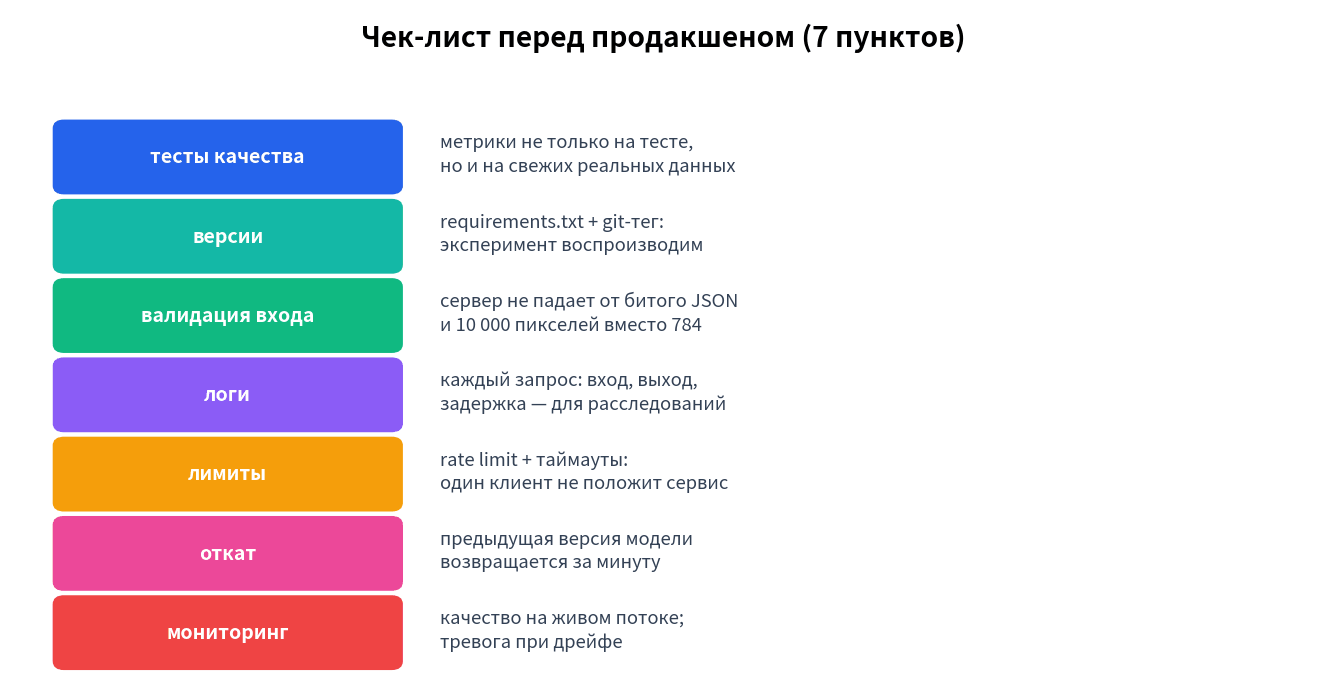

### 5.3. Безопасность и приватность


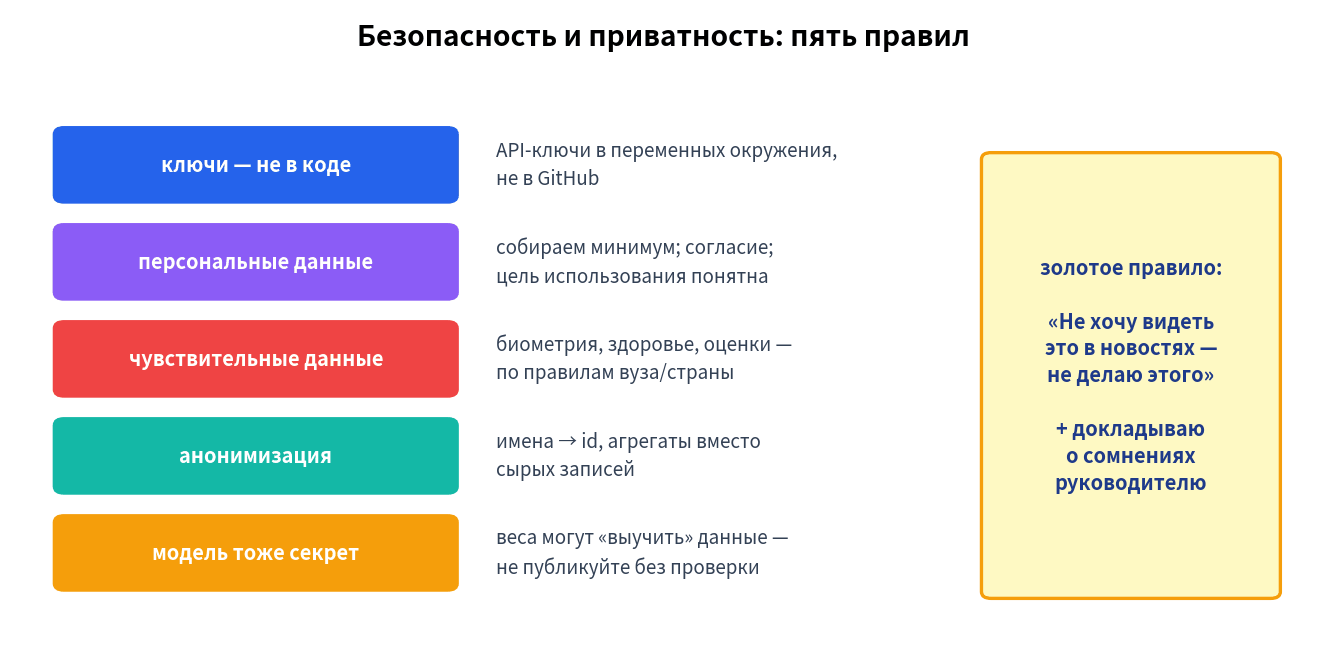

Пара пояснений к правилам. **Ключи в переменных окружения** — утёкший в git ключ оплачивается реальными деньгами (крадут квоты LLM и облаков). **«Модель тоже секрет»** — менее очевидное: существуют атаки извлечения — по вопросам и ответам можно восстановить куски обучающих данных; для медицинских или экзаменационных данных это утечка.

**❓ Вопрос на подумать:** ваш сервис распознаёт цифры, логирует картинки. Какие данные в логах? Кто может их читать? Через полгода они нужны? *(Ответы: изображения-рукописи; любой с доступом к серверу; почти никогда — логировать хэш и метрики, а не сырьё.)*


---







# Этика искусственного интеллекта (45–70 мин)

ИИ — мощный инструмент, но его использование несёт серьёзные риски. Разработчик обязан о них знать.

### ⚖️ Ключевые этические проблемы

1. **Предвзятость данных (数据偏见):** Если в данных для обучения распознавания лиц почти нет людей определённой этнической группы, модель будет хуже их распознавать или ошибаться. *Модель повторяет перекосы общества, отражённые в данных.*
2. **Приватность (隐私):** Использование персональных данных (фото, голос, переписки) для обучения моделей без явного согласия людей.
3. **Дипфейки (深度伪造):** Создание поддельных видео или аудио с использованием ИИ для мошенничества или клеветы.
4. **Авторские права (版权):** Кто владеет текстом или картинкой, сгенерированной ИИ на основе чужих защищённых работ?
5. **Ответственность (责任):** Если автономный автомобиль совершит ДТП или медицинский ИИ поставит неверный диагноз, кто виноват: разработчик, владелец или сама модель?
6. **Академическая честность (学术诚信):** Использование ИИ для написания курсовых работ без указания этого факта является плагиатом.

> 💡 **Золотое правило:** ИИ должен дополнять человека, а не обманывать его или лишать права на принятие решений.

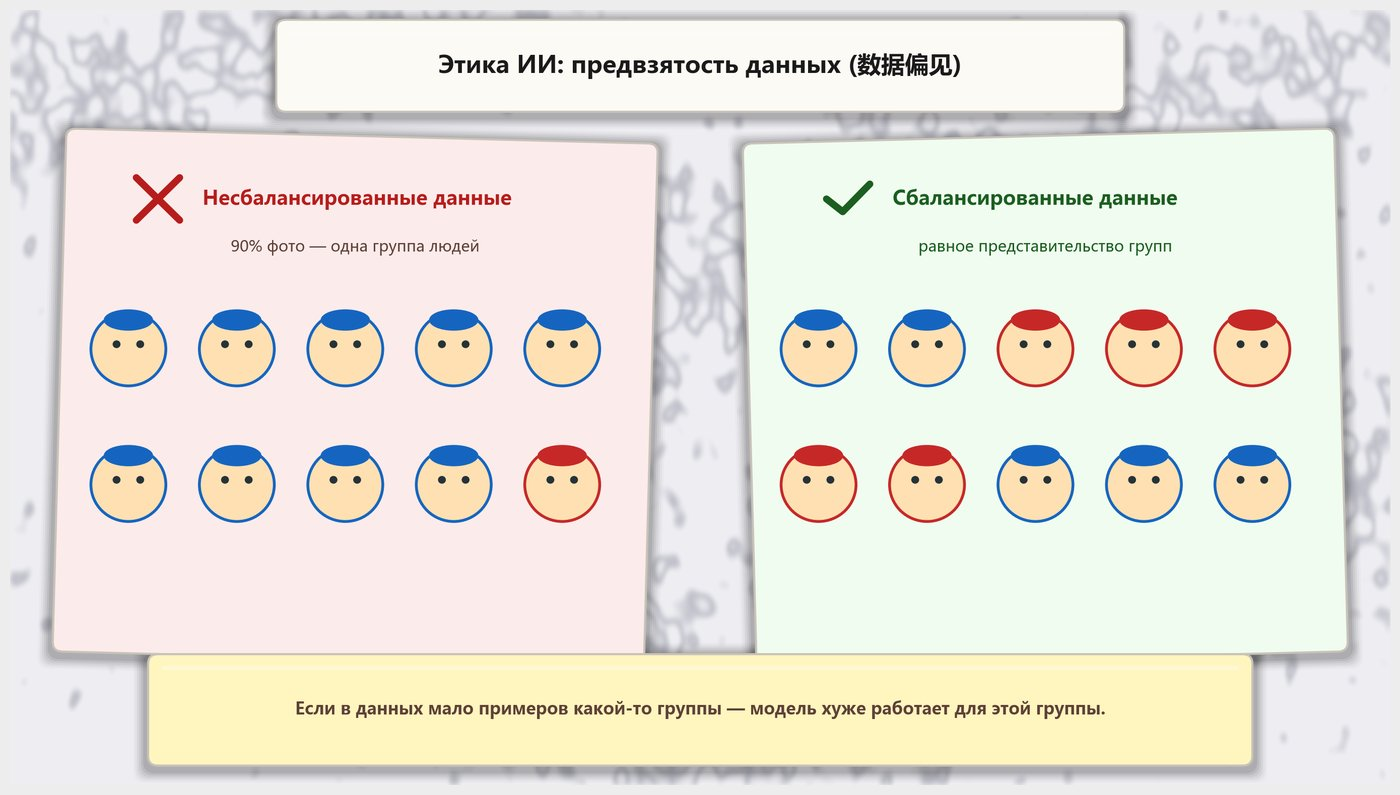


## 1. Предвзятость данных (数据偏见)

**Суть:** модель учится на данных. Если в данных мало примеров какой-то группы людей, модель хуже работает для этой группы.

**Реальные примеры:**
- Системы распознавания лиц хуже работали на тёмнокожих людях, потому что обучающие наборы были собраны преимущественно на светлокожих.
- Кредитные скоринги иногда дискриминировали жителей определённых районов — потому что исторические данные отражали прошлые предрассудки.
- Переводчики часто присваивали «женский» род профессиям вроде «медсестра» и «мужской» — «инженер».

**Что делать?** Собирать сбалансированные данные, проверять модель на разных группах, публиковать отчёты о справедливости.


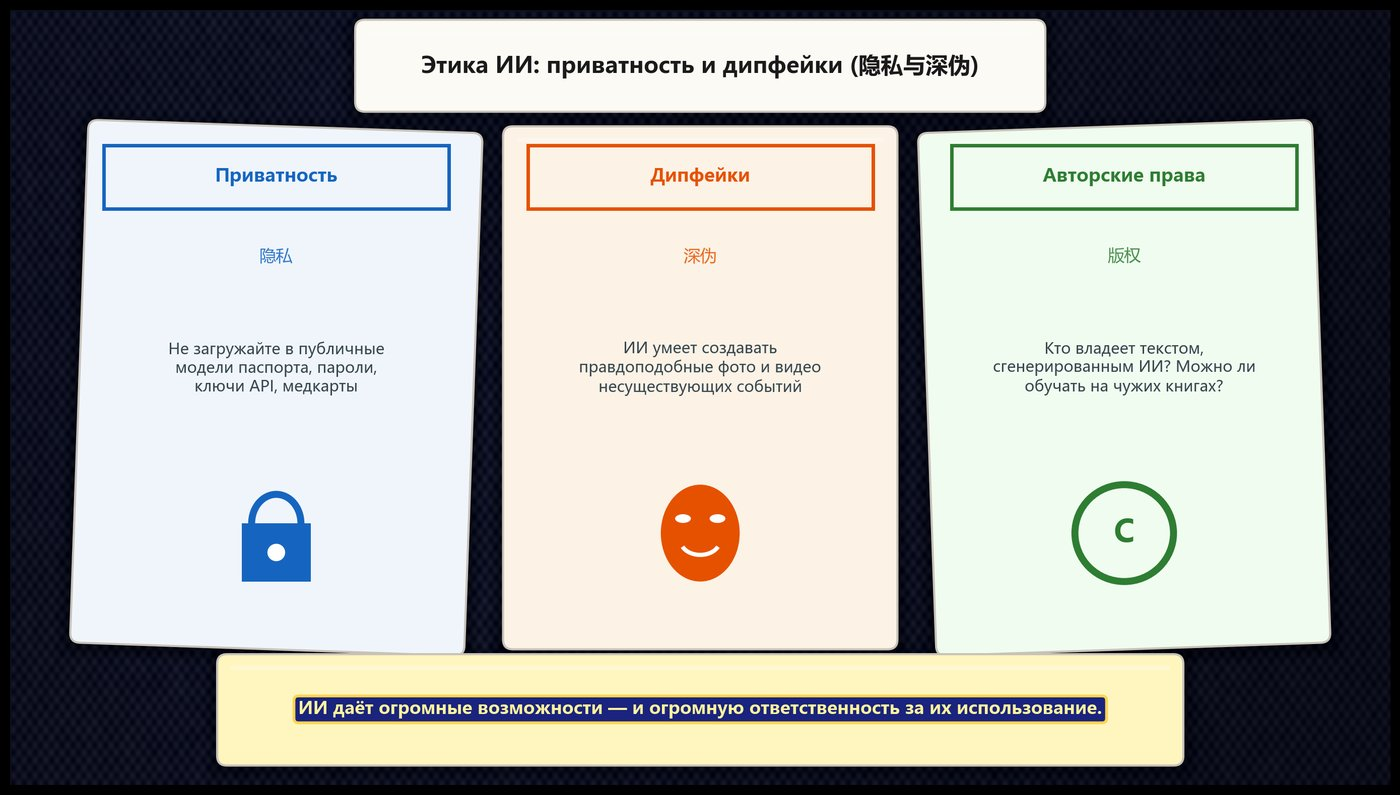

## 2. Приватность (隐私)
**Никогда не загружайте в публичные LLM:**
- паспортные данные, ID-карты;
- пароли и ключи API;
- медицинские диагнозы;
- финансовые документы компании;
- личную переписку без согласия.

Провайдер модели может сохранить ваш запрос и использовать для обучения. Или утечка произойдёт позже.

## 3. Дипфейки (深伪, Deepfake)

Современные модели умеют создавать:
- фотореалистичные лица несуществующих людей;
- видео, где реальный человек говорит то, чего не говорил;
- голос, неотличимый от настоящего.

Это используется в мошенничестве (подделка голоса начальника), в политической пропаганде, в травле. **Всегда проверяйте сенсационные видео и аудио по независимым источникам.**

## 4. Авторские права (版权)

Открытые вопросы индустрии:
- Можно ли обучать модель на книгах, картинах и музыке без разрешения авторов?
- Кто владеет текстом, сгенерированным ИИ по вашему промпту — вы, провайдер модели или никто?
- Как компенсировать авторам, чьи труды использованы в обучении?

В 2025–2026 гг. суды КНР, ЕС и США активно формируют прецеденты.

## 5. Ответственность за ошибки

Если беспилотный автомобиль сбил пешехода — кто виноват: производитель, программист, владелец, сам ИИ? Если языковая модель дала ложный медицинский совет — кто отвечает? **ИИ — это инструмент, ответственность всегда на человеке, который его применяет.**

## 6. Честное использование в учёбе

| Можно | Нельзя |
|-------|--------|
| Спрашивать объяснение темы | Сдавать сгенерированный текст как свой |
| Просить проверить ваш код | Просить решить домашнее задание «с нуля» |
| Искать идеи для проекта | Копировать проект целиком |
| Уточнять формулировки | Притворяться, что ИИ — это вы |

<div style='background-color: #FFEBEE; padding: 15px; border-left: 5px solid #C62828; margin: 20px 0;'>
<b>💡 Главное правило:</b> ИИ — ваш помощник, а не замена. Если вы не можете объяснить код или текст, который сдали, — вы его не написали.
</div>

## 4. Безопасность данных и правила КНР (70–85 мин)

В Китае действует строгое законодательство в сфере цифровых технологий. Каждый разработчик должен соблюдать три основных закона:

## Три ключевых закона

### 1. Закон о защите персональной информации (个人信息保护法, PIPL)

Регулирует, как собирать, хранить и использовать данные о людях. Основные требования:
- **Согласие:** собирать данные только с явного согласия человека;
- **Минимум:** брать только те данные, которые действительно нужны;
- **Прозрачность:** объяснять, зачем данные и как будут использоваться;
- **Право на удаление:** человек может потребовать удалить свои данные;
- **Штрафы:** до 5 % годового оборота компании.

### 2. Закон о безопасности данных (数据安全法)

Вводит классификацию данных:
- **Обычные** — стандартные требования;
- **Важные (重要数据)** — особый режим хранения и передачи;
- **Ключевые (核心数据)** — максимальная защита, связанные с национальной безопасностью.
- Регулирует трансграничную передачу данных.
  
Обязанности компаний: аудиты, защита от утечек, отчётность при инцидентах.

### 3. Временные меры по управлению сервисами генеративного ИИ (生成式人工智能服务管理暂行办法)

Приняты в 2023 году специально для LLM и генеративных моделей:
- Запрещено генерировать контент, нарушающий законы, или контент, основанный на украденных данных.
- Сгенерированный контент должен отражать основные социалистические ценности.
- **Маркировка:** сгенерированный контент должен быть помечен;
- **Проверка фактов:** провайдеры отвечают за достоверность;
- **Запрет дипфейков** без согласия изображённых людей;
- **Защита несовершеннолетних** от вредного контента;
- **Регистрация алгоритмов** в Cyberspace Administration of China (CAC).



## Практические правила для студентов

✅ **Что можно:**
- Использовать учебные наборы данных (iris, digits, MNIST);
- Экспериментировать с LLM на общих темах;
- Тренироваться на своих собственных данных.

### 🛡️ Практические правила безопасности для студента
- ✅ **Всегда** проверяйте факты, сгенерированные ИИ, особенно в учебных работах.
- ✅ **Указывайте**, что часть текста или кода была создана с помощью ИИ, если этого требуют правила вуза.

❌ **Что нельзя:**
- Загружать в публичные модели паспорта, ID-карты, медкарты;
- Выкладывать ключи API в GitHub (даже приватный);
- Собирать данные одногруппников без их согласия;
- Генерировать дипфейки реальных людей;
- Использовать ИИ для списывания на экзаменах.




---
## 🎬 Все видеоматериалы лекции 9

Видео к разделам 1–5: путь модели в продакшен — Flask, Docker, API.
### 🇷🇺 РУС · русскоязычные видео (10)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [Интеграция модели с внешним миром - написание API // Демо-занятие курса «Machine Learning. Advanced»](https://vkvideo.ru/video-145052891_456247752) | VK · OTUS-X | 1:27:45 | Л9 §3: веб-сервис — HTTP-дверь к модели ·[добавлено] | X |
| 2 | [Flask #1. Что это такое? Простое WSGI-приложение](https://rutube.ru/video/f8c8a9f0a122f12d690e4a75f0ccbde1/) | Rutube · SelfEdu | 11:13 | Л9 §4.1 / П9: первое веб-приложение | X |
| 3 | [Flask #2. Использование шаблонов страниц сайта](https://rutube.ru/video/0bcebc31f3d939b1b191a64b263fddcb/) | Rutube · SelfEdu | 11:30 | П9: раздача HTML-страниц | X |
| 4 | [Flask #3. Контекст приложения и контекст запроса](https://rutube.ru/video/bf1575a182742b8f63d5cd75885a83ba/?playlist=534717) | Rutube · SelfEdu | 07:16 | Л9 §4.1: устройство Flask — контексты | X |
| 5 | [Flask #4. Функция url_for и переменные URL-адреса](https://rutube.ru/video/80ddcd4740242a130954273558f0f8f6/?playlist=534717) | Rutube · SelfEdu | 11:43 | Л9 §4.1: маршруты и URL | X |
| 6 | [Flask #5. Подключение внешних ресурсов и работа с формами](https://rutube.ru/video/c4661253ba3718dbb54e850b3c5769c8/?playlist=534717) | Rutube · SelfEdu | 11:08 | П9: формы и статика | X |
| 7 | [Flask #11. Формирование ответа сервера, декораторы перехвата запроса](https://rutube.ru/video/35ed74e5a35bf007fff2ef3670c86ff2/?playlist=534717) | Rutube · SelfEdu | 14:26 | Л9 §4.1: жизненный цикл запроса | X |
| 8 | [Docker. Что это такое?](https://rutube.ru/video/c405ceaf110c3d144a90a46f2694fc9d/) | Rutube · SelfEdu | 8 мин | Л9 §5: зачем контейнеры  X |
| 9 | [Docker #1. Установка Docker Desktop](https://rutube.ru/video/a3169e2ad9e310877e7c4a00be5fd29f/) | Rutube · SelfEdu | 9 мин | П9 (доп): контейнеризация с нуля  X |
| 10 | [Docker #3. Dockerfile. Создание собственных образов](https://rutube.ru/video/44cfd17cd3211e3d7604d2e2e6a665db/) | Rutube · SelfEdu | 17 мин | Л9 §5 / П10: упаковка сервиса в образ  X |


### 🇨🇳 中文 · китайскоязычные видео (8)

| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [把深度学习模型部署成网页应用有多简单？用Flask实测！](https://www.bilibili.com/video/BV1uJGQzyEmb) | Bilibili · Flask demo | Bilibili / ZH | 16 мин ·| ✓ |
| 2 | [零基础玩转Python Flask框架 — полный курс (42 эпизода)](https://www.bilibili.com/video/BV17r4y1y7jJ/) | Bilibili · 知了传课 | курс (42 эп., ~10,5 ч) | Л9 / П9: полный курс Flask — обзор · [добавлено] | ✓ |
| 3 | [【最快速度搞定Flask-框架教程】5小时项目实战全套教程 (32 эпизода)](https://www.bilibili.com/video/BV11PoTYkEE1/) | Bilibili · 我天生无名目檀 | курс (32 эп., ~5 ч) | Л9 / П9: проектный курс Flask — обзор · [добавлено] | ✓ |
| 4 | [Использование больших моделей через API](https://www.bilibili.com/video/BV1tTWizoExf?p=23)<br>· ориг.: *【进阶篇】通过调用API使用大模型* | Bilibili · 动画进阶 | 6 мин | Л9 §1: API как дверь к модели  ✓ |
| 5 | [FastAPI从入门到实战 — маршруты, DI, Pydantic, асинхронность, ORM, деплой (Bilibili · 黑马程序员)](https://www.bilibili.com/video/BV1zV2QBtE39/) | Bilibili · 黑马程序员 | курс | ⚠ вне Л9/П9: FastAPI, не Flask — обзор · [добавлено] | ✓ |
| 6 | [【整300集】Agent开发从入门到就业 — Agent/RAG/LangChain/FastAPI/知识库 (116 эпизодов)](https://www.bilibili.com/video/BV1PUuq6BEbV/) | Bilibili · 大模型饼饼 | курс (116 эп.) | ⚠ вне Л9/П9: Agent/RAG; FastAPI-раздел — обзор · [добавлено] | ✓ |
| 7 | [【国语】MLOps 从入门到精通](https://www.bilibili.com/video/BV1ENaE6eEiD) | Bilibili · MLOps | Bilibili / ZH | 58 эп. ·| ✓ |
| 8 | [吴恩达 MLOps：生产级机器学习（中文重制）](https://www.bilibili.com/video/BV1q73P6qEx1) | Bilibili · MLOps 吴恩达 | Bilibili / ZH/EN | 82 эп. ·| ✓ |

### 🇬🇧 EN · англоязычные видео (3)

| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [Полный жизненный цикл ML-проекта](https://www.bilibili.com/video/BV1owrpYKEtP?p=83)<br>· ориг.: *83.机器学习项目的完整周期* | Bilibili · 吴恩达 (NG, 2025) | 8:45 | Л9 §1, §4: жизненный цикл модели; MLOps: деплой → мониторинг → дрейф ·[добавлено из подборки] ·[добавлено] | ✓ |
| 2 | [吴恩达《FastAPI for Machine Learning: Live coding an ML web application》 — мастер-класс создателя FastAPI (Себастьян Рамирес), веб-приложение на Stable Diffusion](https://www.bilibili.com/video/BV1kC411b7Se/) | Bilibili · перевод DeepLX-курсов Эндрю Нга | ~1 ч (одна запись) | ⚠ вне Л9/П9: FastAPI + ML — обзор · [добавлено] | ✓ |
| 3 | [使用Flask部署机器学习/深度学习模型](https://www.bilibili.com/video/BV1BL4y1L7tX) | Bilibili · Flask деплой | Bilibili / EN+中字 | 29 мин ·[добавлено] | ✓ |


---
## ❓ Мини-тест и закрепление

**1. Что такое API?**
<details>
<summary>Показать ответ</summary>
API (应用程序接口) — это контракт между двумя программами: «если ты пришлёшь запрос в таком-то формате, я верну ответ в таком-то формате». Аналогия — окошко в ресторане: клиент отдаёт заказ, кухня возвращает блюдо, не показывая, как оно готовится.
</details>

**2. Почему нельзя вставлять в чат с моделью чужие персональные данные?**
<details>
<summary>Показать ответ</summary>
Провайдер модели может сохранить ваш запрос и использовать для обучения, либо данные могут попасть в утечку. Это нарушает Закон КНР о защите персональной информации (个人信息保护法) и может причинить вред людям, чьи данные вы передали.
</details>

**3. Приведите пример предвзятости в данных.**
<details>
<summary>Показать ответ</summary>
Если система распознавания лиц обучалась преимущественно на фото светлокожих людей, она будет хуже узнавать тёмнокожих людей. Или кредитный скоринг, обученный на исторических данных с предрассудками, может несправедливо отказывать жителям определённых районов.
</details>

**4. Назовите три закона КНР, регулирующих работу с данными и ИИ.**
<details>
<summary>Показать ответ</summary>
1. 个人信息保护法 — Закон о защите персональной информации.<br>
2. 数据安全法 — Закон о безопасности данных.<br>
3. 生成式人工智能服务管理暂行办法 — Временные меры по управлению сервисами генеративного ИИ.
</details>

**5. Чем локальное развёртывание отличается от облачного?**
<details>
<summary>Показать ответ</summary>
Локальное (host='127.0.0.1') работает только на вашем компьютере — удобно для тестов. Облачное (Alibaba Cloud, Tencent Cloud, Huawei Cloud) даёт публичный IP-адрес, и сервисом могут пользоваться люди через интернет — это нужно для реальных продуктов.
</details>

### Контрольные вопросы

Нажмите на вопрос, чтобы раскрыть образец ответа.

**1. Назовите три отличия продукта от учебного ноутбука. Почему «работает у меня» не равно «работает у пользователей»?**
<details>
<summary>Показать ответ</summary>
<b>1.</b> Другие пользователи — не разработчик, им нужны интерфейс и документация; <b>2.</b> другие данные — реальный поток вместо учебной выборки; <b>3.</b> другая среда — нагрузка, сбои, безопасность. «Работает у меня» ≠ у пользователей, потому что в бою другие условия: свет, устройства, объём запросов, дрейф данных.
</details>

**2. Что именно сохраняется в файл модели для scikit-learn и для PyTorch? Почему веса называют «дипломом» модели?**
<details>
<summary>Показать ответ</summary>
<b>scikit-learn:</b> joblib.dump сериализует весь конвейер (нормировщик + модель) одним файлом. <b>PyTorch:</b> в файл уходит словарь весов `torch.save(model.state_dict())` — архитектуру сначала создают кодом, затем наполняют весами. «Диплом»: накопленный опыт живёт именно в весах — код без них пустая архитектура, а веса переносят модель с ноутбука на сервер.
</details>

**3. Объясните аналогию API и ресторана: что в ней меню, заказ, кухня и блюдо?**
<details>
<summary>Показать ответ</summary>
<b>Меню</b> — документация API (какие маршруты и форматы существуют); <b>заказ</b> — HTTP-запрос клиента; <b>кухня</b> — сервер с моделью, где скрыты все детали; <b>блюдо</b> — ответ в JSON, упакованный по стандарту. Клиенту не нужно знать «рецепт» — только контракт.
</details>

**4. Что такое дрейф данных? Приведите пример для сервиса распознавания цифр и два способа защиты.**
<details>
<summary>Показать ответ</summary>
Дрейф — <b>изменение распределения реальных данных со временем</b>, при котором точность падает «сама по себе». Пример: люди пишут цифры иначе, чем в базе 1990-х; другой сканер или освещение. Защита: <b>мониторинг</b> входов и метрик + периодическое <b>дообучение на свежих данных</b>.
</details>

**5. Назовите пять показателей «пульса» сервиса. Почему внезапный всплеск ответов «единица» — тревожный сигнал?**
<details>
<summary>Показать ответ</summary>
<b>1.</b> Доля запросов с ошибками; <b>2.</b> среднее время ответа; <b>3.</b> средняя уверенность модели; <b>4.</b> распределение предсказанных классов; <b>5.</b> частота запросов. Всплеск «единиц»: сама модель не менялась, значит сломался конвейер данных — например, выравнивание изображения, и 90% картинок «похожи» на единицу.
</details>

**6. Почему клиентское приложение не должно получать веса модели на борт? Назовите три причины.**
<details>
<summary>Показать ответ</summary>
<b>1. Секрет:</b> веса утекут — существуют атаки извлечения, восстанавливающие куски обучающих данных. <b>2. Обновления:</b> каждое дообучение — обновление приложения у всех пользователей. <b>3. Мощность:</b> мобильное устройство не потянет большую модель, а сервер справляется и быстрее.
</details>

**7. Что сломается, если задеплоить модель без StandardScaler из пайплайна?**
<details>
<summary>Показать ответ</summary>
Признаки придут в модель в другой шкале (или вовсе без нормировки) — <b>вход не тот, на котором модель училась</b>, и точность рушится. Именно поэтому классические ошибки №1: «сохранили модель, но не scaler». Лечится пайплайном: scaler сохраняется и загружается вместе с моделью одним файлом.
</details>

**8. Зачем /predict отвечает JSON, а не HTML-страницей?**
<details>
<summary>Показать ответ</summary>
Клиент /predict — <b>программа</b>, а не человек: JSON легко разобрать любому приложению (мобильному, сайту, скрипту). HTML — формат «для глаз», его пришлось бы парсить хрупкими регэкспами. Контракт «запрос JSON → ответ JSON» понятен всем языкам.
</details>

**9. Веса загружаются joblib.load при старте сервера, а не в каждом запросе. Почему?**
<details>
<summary>Показать ответ</summary>
Загрузка весов — <b>секунды</b>, а запрос должен обрабатываться за <b>миллисекунды</b>. Грузим один раз при старте — модель живёт в памяти, каждый запрос обрабатывается мгновенно; иначе каждый ответ будет с задержкой в секунды.
</details>

**10. Точность инспекции упала с 97% до 89% за квартал, код не менялся. Ваши гипотезы и действия?**
<details>
<summary>Показать ответ</summary>
Гипотезы: <b>дрейф данных</b> (новый поставщик, изменилось покрытие деталей), <b>сломался препроцессинг</b> (обновились версии библиотек), <b>изменился входной поток</b> (камера, освещение, настройка линии). Действия: проверить мониторинг и распределение входов, прогнать эталонный тест-набор, дообучить модель на свежих данных.
</details>

**11. Чем MLOps-цикл отличается от «обучили и забыли»?**
<details>
<summary>Показать ответ</summary>
MLOps — <b>цикл</b>: данные → обучение → тест → деплой → мониторинг → (дрейф?) → переобучение. «Обучили и забыли» — разовое действие: модель стареет молча, и падение точности замечают пользователи, а не команда. В MLOps дрейф ловит мониторинг, и модель возвращается в строй до жалоб.
</details>

**12. Почему API-ключ нельзя положить в код репозитория? Как правильно?**
<details>
<summary>Показать ответ</summary>
Утёкший из репозитория ключ тратят за вас: квоты LLM, облака, реальные деньги — и ключ остаётся в <b>истории git навсегда</b>, даже после удаления. Правильно: переменные окружения или секрет-менеджер; в git — только ссылка, сам ключ в .gitignore.
</details>

**13. Сервис оплаты лицом и сервис ночных отчётов — какой класс по скорости? Какие компромиссы возникнут?**
<details>
<summary>Показать ответ</summary>
Оплата лицом — <b>реальное время</b> (миллисекунды): нужен GPU, квантизация, оптимизация; компромисс — дорогая инфраструктура. Ночные отчёты — <b>батч</b> (часы): дешёвый обычный сервер, можно брать точные «тяжёлые» модели; компромисс — результаты только к утру.
</details>


## Заметки для преподавателя


- **Демонстрация Flask:** Лучше всего показать работу Flask в реальном времени. Запустите `app.py` в терминале, а затем в Jupyter Notebook выполните ячейку с `requests.post`, чтобы студенты увидели, как «клиент» получает ответ от «сервера».
- **Обсуждение этики:** Спросите студентов: «Если вы создаёте приложение для университета, какие данные студентов вы имеете право собирать, а какие нет?» Это свяжет теорию с их реальностью.
- **Важно для Практики 8:** Убедитесь, что у всех студентов установлена библиотека `flask` и `requests` в их окружении `ai` перед началом следующего занятия.


## 📚 Глоссарий Лекции 9 (词汇表)

Термины внедрения и MLOps (термины этики — в Лекции 10).

| Термин (рус) | English | 中文 | Пояснение |
|--------------|---------|------|-----------|
| Развёртывание (деплой) | Deployment | 部署 | Запуск модели в эксплуатацию: API, edge, библиотека. |
| Артефакт | Artifact | 产物 | Файл-результат обучения: .pth, .pkl, .onnx; сущность для версионирования. |
| .pth | .pth (PyTorch state dict) | PyTorch模型文件 | Сохранённые веса PyTorch-модели; загружаются в state_dict. |
| joblib | joblib | joblib | Сериализация sklearn-моделей с полной цепочкой препроцессинга. |
| Flask | Flask | Flask | Лёгкий Python веб-фреймворк; идеален для деплоя ML-сервисов. |
| API | API | 应用程序接口 | Контракт общения программ через запросы и ответы. |
| Маршрут (endpoint) | Endpoint | 路由 | URL, обрабатывающий запрос; в Flask — декоратор @app.route. |
| JSON | JSON | 数据交换格式 | Текстовый формат обмена данными; стандарт в API. |
| HTTP | HTTP | 超文本传输协议 | Протокол веб-запросов; методы GET (получить), POST (отправить). |
| REST | REST | 表述性状态转移 | Архитектурный стиль API на HTTP-методах и ресурсах. |
| MLOps | MLOps | 机器学习运维 | ML + DevOps: мониторинг, переобучение, откат модели в продакшене. |
| Мониторинг | Monitoring | 监控 | Слежение за метриками сервиса в продакшене: latency, ошибки, дрейф. |
| Дрейф данных | Data drift | 数据漂移 | Распределение новых данных отличается от обучающих; точность падает. |
| Переобучение (в проде) | Retraining | 再训练 | Повторное обучение на свежих данных; борется с дрейфом. |
| Откат (rollback) | Rollback | 回滚 | Возврат к предыдущей версии модели при падении метрик. |
| A/B-тест | A/B test | A/B测试 | Сравнение двух версий модели на живом трафике. |
| Latency | Latency | 延迟 | Время ответа сервиса; ключевая метрика UX. |
| Edge-деплой | Edge deployment | 边缘部署 | Модель работает на устройстве (телефон, IoT), а не в облаке. |


## 🎓 Итоги Лекции 9

Лекция провела через четыре пути внедрения модели (библиотека, локальный сервис, облачный API, edge), артефакты и воспроизводимость, архитектуру Flask-сервиса и маршрут /predict, жизненный цикл MLOps (мониторинг, дрейф, переобучение, откат) и базовую безопасность.

### 🔑 Главные выводы

1. Четыре пути внедрения: библиотека, локальный сервис, облачный API, edge. Выбор = данные + задержка + обслуживание.
2. Деплой = артефакты: веса + нормировщик + requirements + git-тег. joblib сохраняет конвейер целиком.
3. Веб-сервис: клиент → POST /predict (JSON) → Flask → model.predict → JSON. Модель обновляется на сервере для всех клиентов сразу.
4. Модель в бою стареет: дрейф данных лечится мониторингом и циклом MLOps, а не «надеемся, что ничего не изменилось».
5. Скорость: батч/секунды/миллисекунды; ускорение — батчинг, квантизация, ONNX.
6. Чек-лист продакшена: тесты, версии, валидация, логи, лимиты, откат, мониторинг. Безопасность: ключи в env, минимум данных, модель — тоже секрет.

### 📝 Домашнее задание

1. **Артефакты.** Обучите любую модель лекции 4 на ирисах и соберите «пакет деплоя»: model.pkl + requirements.txt + README на 10 строк (как запустить). Проверьте загрузку в новом процессе.
2. **Свой маршрут.** Расширьте мини-Flask: добавьте маршрут `/health` (возвращает `{"status": "ok"}`) и `/info` (имя модели и дата обучения). Протестируйте curl'ом.
3. **Расследование дрейфа.** Придумайте сценарий дрейфа для сервиса вашей специальности (например, детектор брака, рекомендации столовой). Напишите: что сместилось, как заметить, что делать. Полстраницы.

### 📅 Следующее занятие

**Лекция 10: Этика ИИ, риски и итоги курса**

**Практика 9: Веб-сервис на Flask (завершение) · Практика 10: Итоговый проект**

---

<center><i>Преподаватель: _______________</i></center>
<center><i>Дата проведения: _______________</i></center>